In [2]:
# ## 목차
# 1. 설치 & 임포트
# 2. mmCIF 파일 불러오기
# 3. 모델·체인·잔기 탐색
# 4. Cα 좌표 추출 & 시각화
# 5. 삼각 프레임(회전·이동) 계산 예시
# 6. 미니 과제

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from Bio.PDB import MMCIFParser

In [2]:
print("BioPython version:")
import Bio
print(Bio.__version__)

BioPython version:
1.85


In [3]:
# cif 파일 규칙
# 1,2,3, ..., A, B, ... 숫자 : DB에 등록된 순서. 1의 경우 1970-90년대에 발급된 번호
# 3개 알파벳 글지 : 연구자가 축약한 글자

In [4]:
DATA_DIR = Path("/home/bio_science/data/protein")
cif_path = DATA_DIR / "1aat.cif"

In [7]:
parser = MMCIFParser(QUIET=True)
structure = parser.get_structure("demo", cif_path)

In [8]:
print("총 모델 수:", len(structure))

총 모델 수: 1


In [21]:
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
cif_info = MMCIF2Dict(cif_path)

In [22]:
print("파일 제목 :", cif_info['_struct.title'][0])
print("단백질 이름 :", cif_info['_entity.pdbx_description'][0])
print("생물 종    :", cif_info.get('_entity_src_nat.pdbx_organism_scientific',
                                  cif_info.get('_entity_src_gen.pdbx_gene_src_scientific_name', ['?']))[0])

파일 제목 : OXOGLUTARATE-INDUCED CONFORMATIONAL CHANGES IN CYTOSOLIC ASPARTATE AMINOTRANSFERASE
단백질 이름 : CYTOSOLIC ASPARTATE AMINOTRANSFERASE
생물 종    : Gallus gallus


In [14]:
## 3  모델 → 체인 → 잔기 구조 탐색

In [15]:
model0 = structure[0]

In [17]:
print("체인 ID 목록:", [chain.id for chain in model0])

체인 ID 목록: ['A', 'B']


두 개가 들어가는 경우

In [29]:
chainA = model0["A"]
print("잔기 개수:", len(chainA))
print("처음 5개 residue 이름:", [res.get_resname() for res in list(chainA)[:5]])

잔기 개수: 411
처음 5개 residue 이름: ['ALA', 'ALA', 'SER', 'ILE', 'PHE']


In [23]:
# ## 4  Cα 좌표 추출 & 3‑D 산점도

In [24]:
coords = [res["CA"].coord for res in chainA if "CA" in res]
ca_coords = np.vstack(coords)  # (L,3)

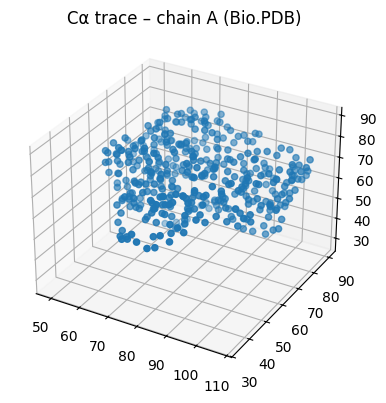

In [25]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*ca_coords.T)
ax.set_title("Cα trace – chain A (Bio.PDB)")
plt.tight_layout()


In [26]:
# ## 5  잔기 **Frame (회전·이동)** 계산 예시
# NanoFold 전처리의 `compute_residue_frames` 와 유사한 간단 구현.
# 세 backbone 원자 N‑CA‑C 를 기준으로 내적정규좌표계를 잡습니다.

In [27]:
from numpy.linalg import norm

In [28]:
def residue_frame(residue):
    """Return 3×3 rotation R and 3‑D translation t for a residue."""
    if not all(at in residue for at in ("N", "CA", "C")):
        raise ValueError("Backbone atoms missing")
    n, ca, c = (residue[a].coord for a in ("N", "CA", "C"))
    e1 = (c - ca) / norm(c - ca)
    e2 = np.cross((n - ca), e1)
    e2 /= norm(e2)
    e3 = np.cross(e1, e2)
    R = np.stack([e1, e2, e3], axis=-1)  # 3×3
    t = ca
    return R, t

R0, t0 = residue_frame(chainA[0])
print("R shape", R0.shape, "t", t0)


KeyError: (' ', 0, ' ')

In [ ]:
# 네트워크 차단 시 → RCSB REST API (featherweight) or wget "https://files.rcsb.org/download/{PDBList()
pdb_ids = ["1crn","1a3n"]
for pid in pdb_ids:
    pdb1.retrieve_pdb_file(pid, pdir=DATA_DIR, file_format='mmCif', overwrite=False)

In [ ]:
import gemmi
st = gemmi.read_structure(str(cif_path))

st, len(st)

In [18]:
# gemmi로 확인
print("모델 수:", len(st))            # 1
print("체인 ID:", [c.name for c in st[0]])  # ['A']

모델 수: 1
체인 ID: ['A', 'B']
